# NexaTel Customer Churn Analytics project

## Phase 2 — Exploratory Data Analysis  

In [59]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the cleaned data from Phase 1
clean_folder = Path("phase1_output") / "cleaned_data"

if not clean_folder.is_dir():
    raise FileNotFoundError(
        "Cleaned data folder not found. Save this notebook "
        "inside NEXATEL_PROJECT, beside phase1_output."
    )

eda_tables = {
    file.stem: pd.read_csv(file)
    for file in sorted(clean_folder.glob("*.csv"))
}

# Create a folder for the Phase 2 charts
chart_folder = Path("phase2_output") / "charts"
chart_folder.mkdir(parents=True, exist_ok=True)

# Customer table for our first chart
customers = eda_tables["customers"].copy()

assert customers["customer_id"].notna().all(), "Missing customer IDs found."
assert customers["customer_id"].is_unique, "Duplicate customer IDs found."
assert customers["customer_status"].isin(
    ["Active", "Churned"]
).all(), "Unexpected customer statuses found."

print("Tables loaded:", len(eda_tables))
print("Total customers:", len(customers))
print("\nCustomer status counts:")
display(customers["customer_status"].value_counts())

print("Charts will be saved to:", chart_folder.resolve())

Tables loaded: 24
Total customers: 19000

Customer status counts:


customer_status
Active     15494
Churned     3506
Name: count, dtype: int64

Charts will be saved to: C:\Users\Anushka Tyagi\NEXATEL_PROJECT\phase2_output\charts


# Chart 1: overall churn KPI and customer-status bar chart

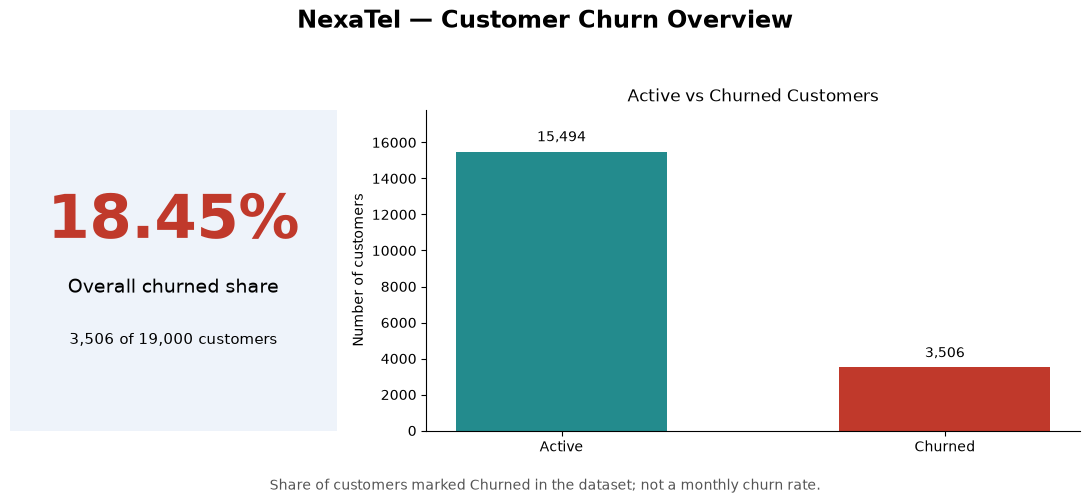

Chart saved: phase2_output\charts\01_overall_churn.png


In [60]:
# Calculate the share of customers marked Churned
status_counts = (
    customers["customer_status"]
    .value_counts()
    .reindex(["Active", "Churned"], fill_value=0)
)

total_customers = len(customers)
churned_customers = int(status_counts["Churned"])
churn_pct = churned_customers / total_customers * 100

fig, axes = plt.subplots(
    1, 2, figsize=(11, 5),
    gridspec_kw={"width_ratios": [1, 2]}
)

# KPI card
axes[0].set_facecolor("#EEF3FA")
axes[0].text(
    0.5, 0.65, f"{churn_pct:.2f}%",
    ha="center", va="center",
    fontsize=44, fontweight="bold", color="#C0392B"
)
axes[0].text(
    0.5, 0.43, "Overall churned share",
    ha="center", fontsize=14
)
axes[0].text(
    0.5, 0.27,
    f"{churned_customers:,} of {total_customers:,} customers",
    ha="center", fontsize=11
)
axes[0].set_xticks([])
axes[0].set_yticks([])
for spine in axes[0].spines.values():
    spine.set_visible(False)

# Customer-status bar chart
bars = axes[1].bar(
    status_counts.index,
    status_counts.values,
    color=["#238B8D", "#C0392B"],
    width=0.55
)

axes[1].bar_label(
    bars,
    labels=[f"{value:,}" for value in status_counts.values],
    padding=5
)
axes[1].set_title("Active vs Churned Customers")
axes[1].set_ylabel("Number of customers")
axes[1].set_ylim(0, status_counts.max() * 1.15)
axes[1].spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "NexaTel — Customer Churn Overview",
    fontsize=17, fontweight="bold"
)
fig.text(
    0.5, 0.02,
    "Share of customers marked Churned in the dataset; not a monthly churn rate.",
    ha="center", fontsize=10, color="#555555"
)

plt.tight_layout(rect=[0, 0.06, 1, 0.93])

chart_path = chart_folder / "01_overall_churn.png"
fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_path)

## Chart 1- Observation

## Of the 19,000 customers, 3,506 (18.45%) are marked Churned, while 15,494 (81.55%) remain Active. Approximately one in five customers in the dataset has churned. This percentage describes the dataset’s overall customer-status mix and should not be compared directly with a monthly churn target.

# Chart 2: churn by billing cycle—Monthly versus Annual

In [61]:
subscriptions = eda_tables["subscriptions"].copy()

print("Subscription billing cycles:")
display(
    subscriptions["billing_cycle"].value_counts(dropna=False)
)

# One row per customer and billing cycle
customer_cycles = subscriptions[
    ["customer_id", "billing_cycle"]
].drop_duplicates()

cycles_per_customer = customer_cycles.groupby(
    "customer_id"
)["billing_cycle"].nunique()

print(
    "Customers with multiple billing cycles:",
    (cycles_per_customer > 1).sum()
)

print(
    "Customers without a subscription record:",
    (~customers["customer_id"].isin(
        subscriptions["customer_id"]
    )).sum()
)

print(
    "Subscription rows with missing billing cycle:",
    subscriptions["billing_cycle"].isna().sum()
)

Subscription billing cycles:


billing_cycle
Monthly    15107
Annual      5416
Name: count, dtype: int64

Customers with multiple billing cycles: 586
Customers without a subscription record: 0
Subscription rows with missing billing cycle: 0


,Customers,Churned,Churned Share %
billing_cycle_group,,,
Monthly,13680,3089,22.58
Annual,4734,338,7.14
Both,586,79,13.48


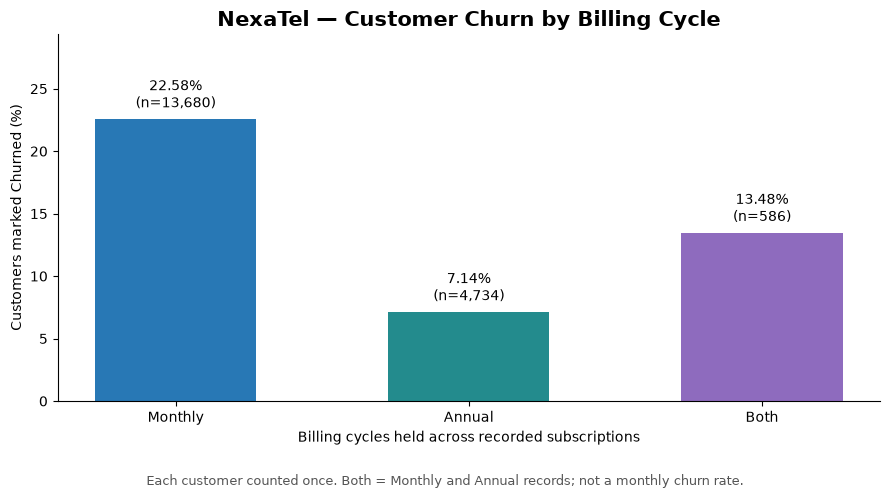

Chart saved: phase2_output\charts\02_churn_by_billing_cycle.png


In [62]:
# Assign each customer to one billing-cycle group
cycle_groups = (
    customer_cycles.groupby("customer_id")["billing_cycle"]
    .agg(lambda values: (
        "Both" if values.nunique() > 1 else values.iloc[0]
    ))
    .rename("billing_cycle_group")
    .reset_index()
)

cycle_analysis = customers[
    ["customer_id", "customer_status"]
].merge(
    cycle_groups,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

cycle_analysis["churned"] = (
    cycle_analysis["customer_status"] == "Churned"
)

cycle_summary = (
    cycle_analysis.groupby("billing_cycle_group")
    .agg(
        Customers=("customer_id", "size"),
        Churned=("churned", "sum")
    )
    .reindex(["Monthly", "Annual", "Both"])
)

cycle_summary["Churned Share %"] = (
    cycle_summary["Churned"]
    / cycle_summary["Customers"] * 100
)

assert cycle_summary["Customers"].sum() == len(customers)

display(cycle_summary.round(2))

# Plot percentages to compare groups of different sizes fairly
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    cycle_summary.index,
    cycle_summary["Churned Share %"],
    color=["#2878B5", "#238B8D", "#8E6BBE"],
    width=0.55
)

ax.bar_label(
    bars,
    labels=[
        f"{rate:.2f}%\n(n={count:,})"
        for rate, count in zip(
            cycle_summary["Churned Share %"],
            cycle_summary["Customers"]
        )
    ],
    padding=5
)

ax.set_title(
    "NexaTel — Customer Churn by Billing Cycle",
    fontsize=15, fontweight="bold"
)
ax.set_xlabel("Billing cycles held across recorded subscriptions")
ax.set_ylabel("Customers marked Churned (%)")
ax.set_ylim(
    0, cycle_summary["Churned Share %"].max() * 1.3
)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.5, 0.02,
    "Each customer counted once. Both = Monthly and Annual records; "
    "not a monthly churn rate.",
    ha="center", fontsize=9, color="#555555"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])

chart_path = chart_folder / "02_churn_by_billing_cycle.png"
fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_path)

## Chart-2 Observation

## Monthly-only customers have a churned share of 22.58%, compared with 7.14% for Annual-only customers—a difference of 15.44 percentage points. The 586 customers with both billing cycles have a churned share of 13.48%. This shows an association between billing cycle and customer churn status; it does not prove that annual billing prevents churn.

# Chart 3: churn by tenure band- : 0–3 months, over 3–12 months, over 12–36 months, and over 36 months


,Customers,Churned,Churned Share %
tenure_band,,,
0–3 months,749,561,74.90
>3–12 months,1446,756,52.28
>12–36 months,2836,1026,36.18
>36 months,13969,1163,8.33


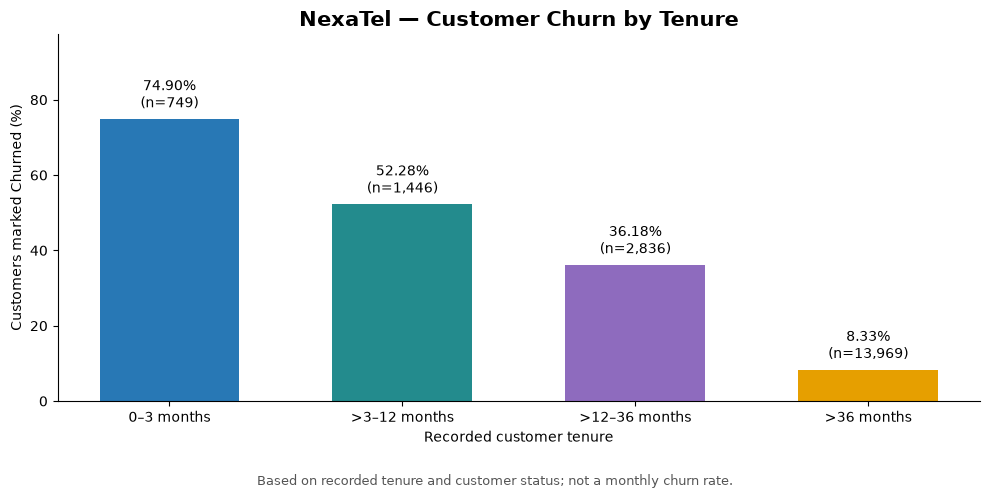

Chart saved: phase2_output\charts\03_churn_by_tenure.png


In [63]:
tenure_analysis = customers[
    ["customer_id", "tenure_months", "customer_status"]
].copy()

tenure = pd.to_numeric(
    tenure_analysis["tenure_months"], errors="coerce"
)

assert tenure.notna().all(), "Missing or nonnumeric tenure found."
assert tenure.ge(0).all(), "Negative tenure found."

labels = ["0–3 months", ">3–12 months", ">12–36 months", ">36 months"]

tenure_analysis["tenure_band"] = pd.cut(
    tenure,
    bins=[0, 3, 12, 36, float("inf")],
    labels=labels,
    include_lowest=True,
    right=True
)

tenure_analysis["churned"] = (
    tenure_analysis["customer_status"] == "Churned"
)

tenure_summary = (
    tenure_analysis.groupby("tenure_band", observed=False)
    .agg(
        Customers=("customer_id", "size"),
        Churned=("churned", "sum")
    )
)

tenure_summary["Churned Share %"] = (
    tenure_summary["Churned"]
    / tenure_summary["Customers"].replace(0, float("nan"))
    * 100
)

assert tenure_summary["Customers"].sum() == len(customers)

display(tenure_summary.round(2))

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    tenure_summary.index.astype(str),
    tenure_summary["Churned Share %"],
    color=["#2878B5", "#238B8D", "#8E6BBE", "#E69F00"],
    width=0.6
)

ax.bar_label(
    bars,
    labels=[
        f"{rate:.2f}%\n(n={count:,})"
        for rate, count in zip(
            tenure_summary["Churned Share %"],
            tenure_summary["Customers"]
        )
    ],
    padding=5
)

ax.set_title(
    "NexaTel — Customer Churn by Tenure",
    fontsize=15, fontweight="bold"
)
ax.set_xlabel("Recorded customer tenure")
ax.set_ylabel("Customers marked Churned (%)")
ax.set_ylim(0, tenure_summary["Churned Share %"].max() * 1.3)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.5, 0.02,
    "Based on recorded tenure and customer status; not a monthly churn rate.",
    ha="center", fontsize=9, color="#555555"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])

chart_path = chart_folder / "03_churn_by_tenure.png"
fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_path)

# Chart 3- Observation

## The churned share decreases across recorded tenure bands: 74.90% for 0–3 months, 52.28% for >3–12 months, 36.18% for >12–36 months, and 8.33% for >36 months. The longest-tenure group still contains the largest number of churned customers (1,163), because it is much larger than the other groups. These are descriptive shares based on recorded tenure, not probabilities of churning within each time interval.

# Chart 4 — churn by number of unresolved complaints

In [64]:
complaints = eda_tables["complaints"].copy()

complaint_status = (
    complaints["status"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

unresolved_counts = (
    complaints.loc[complaint_status.eq("unresolved").fillna(False)]
    .groupby("customer_id")
    .size()
    .rename("unresolved_complaints")
)

complaint_analysis = customers[
    ["customer_id", "customer_status"]
].merge(
    unresolved_counts,
    left_on="customer_id",
    right_index=True,
    how="left",
    validate="one_to_one"
)

complaint_analysis["unresolved_complaints"] = (
    complaint_analysis["unresolved_complaints"]
    .fillna(0)
    .astype(int)
)

complaint_analysis["churned"] = (
    complaint_analysis["customer_status"].eq("Churned")
)

complaint_summary = (
    complaint_analysis
    .groupby("unresolved_complaints")
    .agg(
        Customers=("customer_id", "size"),
        Churned=("churned", "sum")
    )
)

complaint_summary["Churned Share %"] = (
    complaint_summary["Churned"]
    / complaint_summary["Customers"] * 100
)

assert complaint_summary["Customers"].sum() == len(customers)
assert (
    complaint_analysis["unresolved_complaints"].sum()
    == complaint_status.eq("unresolved").fillna(False).sum()
), "Some unresolved complaints did not match a customer."

display(complaint_summary.round(2))

,Customers,Churned,Churned Share %
unresolved_complaints,,,
0,12942,1956,15.11
1,4934,1153,23.37
2,975,325,33.33
3,133,66,49.62
4,15,6,40.00
5,1,0,0.00


,Customers,Churned,Churned Share %
complaint_group,,,
0,12942,1956,15.11
1,4934,1153,23.37
2,975,325,33.33
3+,149,72,48.32


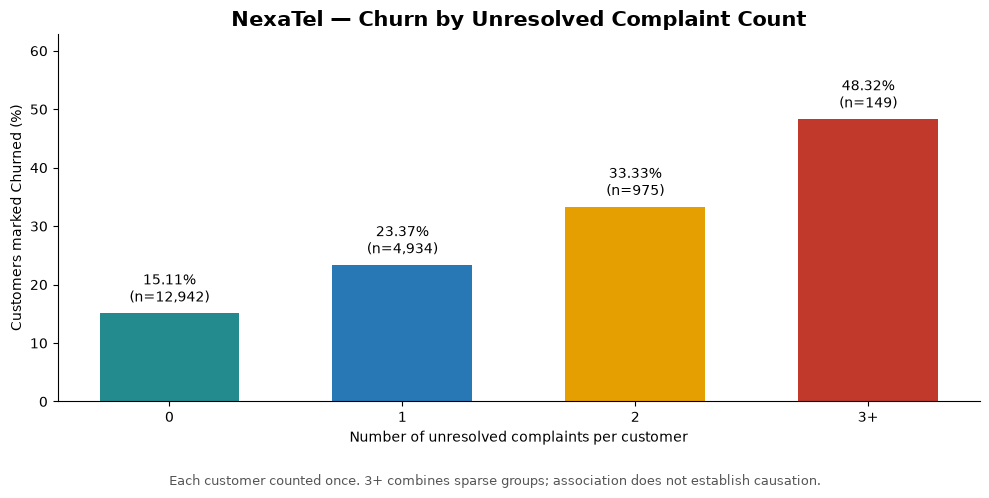

Chart saved: phase2_output\charts\04_churn_by_unresolved_complaints.png


In [65]:
# Group customers into 0, 1, 2, and 3+ unresolved complaints
complaint_analysis["complaint_group"] = (
    complaint_analysis["unresolved_complaints"]
    .clip(upper=3)
    .map({0: "0", 1: "1", 2: "2", 3: "3+"})
)

complaint_chart_summary = (
    complaint_analysis
    .groupby("complaint_group")
    .agg(
        Customers=("customer_id", "size"),
        Churned=("churned", "sum")
    )
    .reindex(["0", "1", "2", "3+"])
)

complaint_chart_summary["Churned Share %"] = (
    complaint_chart_summary["Churned"]
    / complaint_chart_summary["Customers"] * 100
)

display(complaint_chart_summary.round(2))

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    complaint_chart_summary.index,
    complaint_chart_summary["Churned Share %"],
    color=["#238B8D", "#2878B5", "#E69F00", "#C0392B"],
    width=0.6
)

ax.bar_label(
    bars,
    labels=[
        f"{rate:.2f}%\n(n={count:,})"
        for rate, count in zip(
            complaint_chart_summary["Churned Share %"],
            complaint_chart_summary["Customers"]
        )
    ],
    padding=5
)

ax.set_title(
    "NexaTel — Churn by Unresolved Complaint Count",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Number of unresolved complaints per customer")
ax.set_ylabel("Customers marked Churned (%)")
ax.set_ylim(
    0,
    complaint_chart_summary["Churned Share %"].max() * 1.3
)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.5, 0.02,
    "Each customer counted once. 3+ combines sparse groups; "
    "association does not establish causation.",
    ha="center",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])

chart_path = chart_folder / "04_churn_by_unresolved_complaints.png"
fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_path)

 # Chart-4 Observation

# Customers with no unresolved complaints have a churned share of 15.11%,
rising to 23.37% with one, 33.33% with two, and 48.32% with three or more.
The 3+ group contains only 149 customers, so its percentage should be
interpreted cautiously. This association does not establish that unresolved
complaints caused churn or occurred before it.

# Chart 5 — churn by customer segment

,Customers,Churned,Churned Share %
customer_segment,,,
Mass,2932,782,26.67
Value,6196,1275,20.58
Premium,8482,1283,15.13
Enterprise,1390,166,11.94


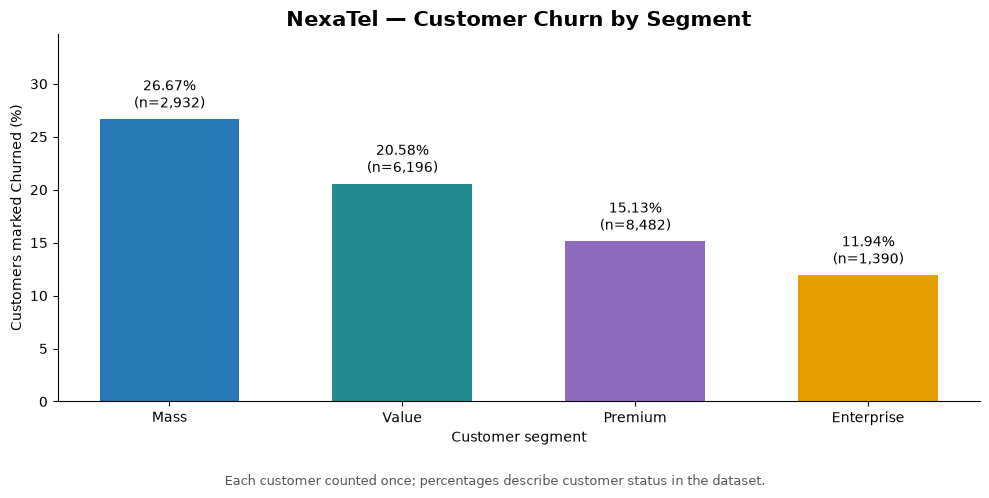

Chart saved: phase2_output\charts\05_churn_by_customer_segment.png


In [66]:
segment_analysis = customers[
    ["customer_id", "customer_segment", "customer_status"]
].copy()

segment_order = ["Mass", "Value", "Premium", "Enterprise"]

assert segment_analysis["customer_segment"].isin(segment_order).all(), (
    "Missing or unexpected customer segments found."
)

segment_analysis["churned"] = (
    segment_analysis["customer_status"].eq("Churned")
)

segment_summary = (
    segment_analysis
    .groupby("customer_segment")
    .agg(
        Customers=("customer_id", "size"),
        Churned=("churned", "sum")
    )
    .reindex(segment_order)
)

segment_summary["Churned Share %"] = (
    segment_summary["Churned"]
    / segment_summary["Customers"] * 100
)

assert segment_summary["Customers"].sum() == len(customers)

display(segment_summary.round(2))

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    segment_summary.index,
    segment_summary["Churned Share %"],
    color=["#2878B5", "#238B8D", "#8E6BBE", "#E69F00"],
    width=0.6
)

ax.bar_label(
    bars,
    labels=[
        f"{rate:.2f}%\n(n={count:,})"
        for rate, count in zip(
            segment_summary["Churned Share %"],
            segment_summary["Customers"]
        )
    ],
    padding=5
)

ax.set_title(
    "NexaTel — Customer Churn by Segment",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Customer segment")
ax.set_ylabel("Customers marked Churned (%)")
ax.set_ylim(0, segment_summary["Churned Share %"].max() * 1.3)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.5, 0.02,
    "Each customer counted once; percentages describe "
    "customer status in the dataset.",
    ha="center",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])

chart_path = chart_folder / "05_churn_by_customer_segment.png"
fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_path)

# Chart -5 Observation

# Mass customers have the highest churned share (26.67%), followed by
Value (20.58%), Premium (15.13%), and Enterprise (11.94%).
Premium nevertheless has the largest number of churned customers
(1,283), slightly above Value (1,275), because its customer base is larger.
This shows why both churned percentages and customer counts matter
when identifying segments for further investigation.

# Chart 6 — Top 10 states by number of churned customers

,state_name,Customers,Churned,Churned Share %
9,Maharashtra,1876,305,16.26
3,Uttar Pradesh,1657,285,17.20
14,Tamil Nadu,1501,280,18.65
4,Rajasthan,1336,244,18.26
13,Karnataka,1164,222,19.07
10,Gujarat,1130,191,16.90
11,Madhya Pradesh,981,182,18.55
15,Kerala,861,162,18.82
16,Andhra Pradesh,832,160,19.23
18,West Bengal,817,157,19.22


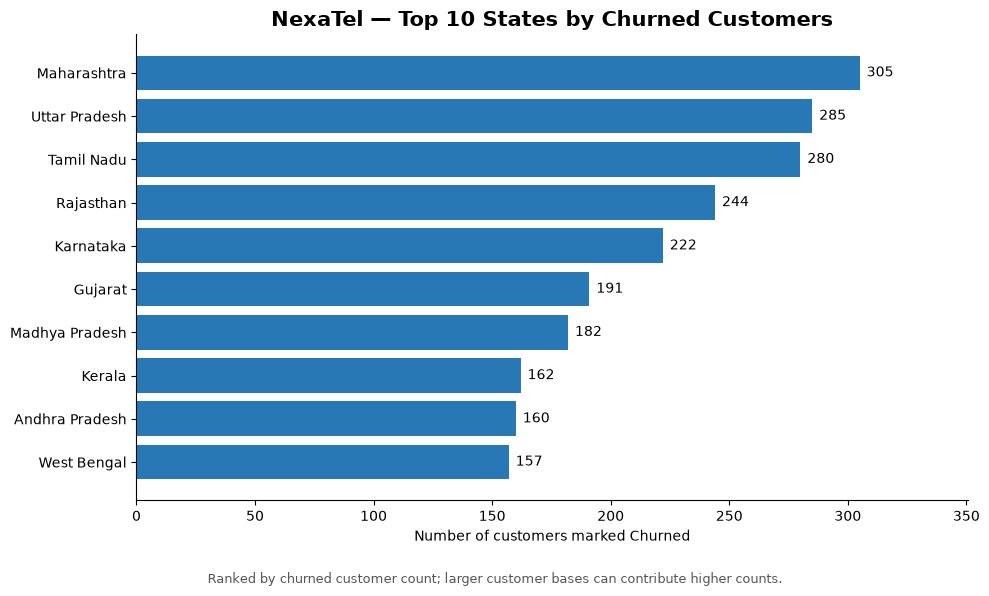

Chart saved: phase2_output\charts\06_top10_states_by_churned_customers.png


In [67]:
states = eda_tables["states"].copy()

# Attach state names without multiplying customer rows
state_analysis = customers[
    ["customer_id", "state_id", "customer_status"]
].merge(
    states[["state_id", "state_name"]],
    on="state_id",
    how="left",
    validate="many_to_one"
)

assert state_analysis["state_name"].notna().all(), (
    "Some customer state IDs have no matching state name."
)

state_analysis["churned"] = (
    state_analysis["customer_status"].eq("Churned")
)

state_summary = (
    state_analysis
    .groupby(["state_id", "state_name"])
    .agg(
        Customers=("customer_id", "size"),
        Churned=("churned", "sum")
    )
    .reset_index()
)

state_summary["Churned Share %"] = (
    state_summary["Churned"]
    / state_summary["Customers"] * 100
)

assert state_summary["Customers"].sum() == len(customers)
assert state_summary["Churned"].sum() == (
    customers["customer_status"].eq("Churned").sum()
)

top10_states = (
    state_summary
    .sort_values(
        ["Churned", "state_name"],
        ascending=[False, True]
    )
    .head(10)
)

display(
    top10_states[
        ["state_name", "Customers", "Churned", "Churned Share %"]
    ].round(2)
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top10_states["state_name"],
    top10_states["Churned"],
    color="#2878B5"
)

ax.invert_yaxis()
ax.bar_label(
    bars,
    labels=[f"{count:,}" for count in top10_states["Churned"]],
    padding=5
)

ax.set_title(
    "NexaTel — Top 10 States by Churned Customers",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Number of customers marked Churned")
ax.set_ylabel("")
ax.set_xlim(0, top10_states["Churned"].max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.5, 0.02,
    "Ranked by churned customer count; larger customer bases "
    "can contribute higher counts.",
    ha="center",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

chart_path = chart_folder / "06_top10_states_by_churned_customers.png"
fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_path)

# Chart-6 Observation

# Maharashtra has the most churned customers (305), followed by Uttar
Pradesh (285) and Tamil Nadu (280). Maharashtra’s churned share
(16.26%) is below the overall 18.45%, showing that a high churned
count does not necessarily mean a high churned percentage.
These rankings identify where customer losses are concentrated,
while percentages provide context for differences in customer-base size.

# Chart 7 — average data usage by city tier

In [68]:
usage = eda_tables["usage_data"].copy()

print("Customer city tiers:")
display(customers["city_tier"].value_counts(dropna=False))

print("\nUsage months:")
display(usage["usage_month"].value_counts(dropna=False).sort_index())

print("\nUsage records per customer:")
display(
    usage.groupby("customer_id")
    .size()
    .value_counts()
    .sort_index()
    .rename_axis("Records per customer")
    .rename("Customer count")
)

print("\nData usage distribution (GB):")
display(
    usage["data_gb_used"]
    .describe(percentiles=[0.5, 0.95, 0.99])
    .round(2)
)

print("\nPhase 1 outlier flags:")
display(usage["usage_outlier_iqr"].value_counts(dropna=False))

print(
    "\nDuplicate customer-month rows:",
    usage.duplicated(["customer_id", "usage_month"]).sum()
)

print(
    "Customers without usage records:",
    (~customers["customer_id"].isin(usage["customer_id"])).sum()
)

Customer city tiers:


city_tier
Tier-2    9211
Tier-3    4930
Metro     4859
Name: count, dtype: int64


Usage months:


usage_month
01-2026    19000
02-2026    19000
03-2026    19000
Name: count, dtype: int64


Usage records per customer:


Records per customer
3    19000
Name: Customer count, dtype: int64


Data usage distribution (GB):


count    57000.00
mean        40.18
std        332.57
min          0.24
50%         19.14
95%         79.08
99%        140.67
max      22172.70
Name: data_gb_used, dtype: float64


Phase 1 outlier flags:


usage_outlier_iqr
False    52520
True      4480
Name: count, dtype: int64


Duplicate customer-month rows: 0
Customers without usage records: 0


,Customers,Mean_monthly_GB,Median_customer_monthly_average_GB
city_tier,,,
Metro,4859,49.19,27.23
Tier-2,9211,41.75,20.00
Tier-3,4930,28.38,13.85


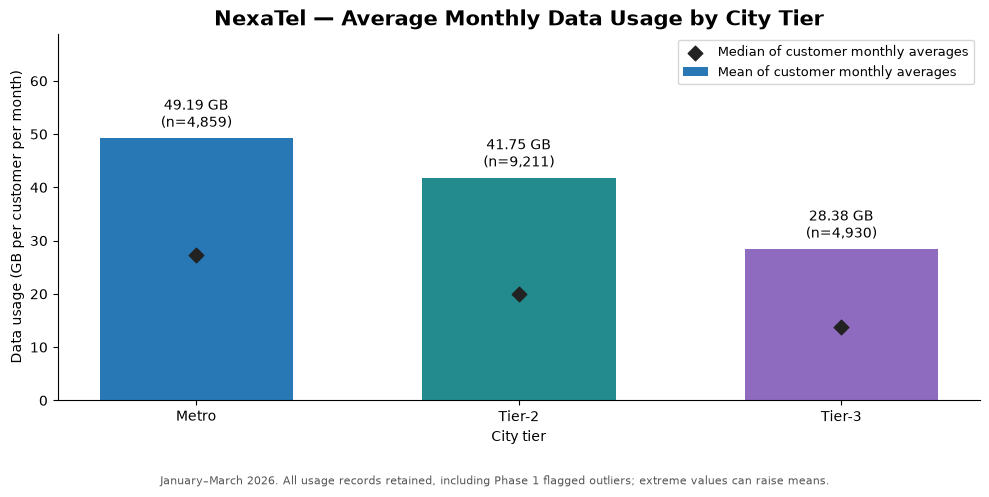

Chart saved: phase2_output\charts\07_average_data_usage_by_city_tier.png


In [69]:
# Calculate average monthly usage for each customer
customer_usage = (
    usage.groupby("customer_id", as_index=False)
    .agg(avg_monthly_gb=("data_gb_used", "mean"))
)

tier_analysis = customers[
    ["customer_id", "city_tier"]
].merge(
    customer_usage,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

tier_order = ["Metro", "Tier-2", "Tier-3"]

assert tier_analysis["city_tier"].isin(tier_order).all()
assert tier_analysis["avg_monthly_gb"].notna().all()

tier_summary = (
    tier_analysis.groupby("city_tier")
    .agg(
        Customers=("customer_id", "size"),
        Mean_monthly_GB=("avg_monthly_gb", "mean"),
        Median_customer_monthly_average_GB=("avg_monthly_gb", "median")
    )
    .reindex(tier_order)
)

assert tier_summary["Customers"].sum() == len(customers)

display(tier_summary.round(2))

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    tier_summary.index,
    tier_summary["Mean_monthly_GB"],
    color=["#2878B5", "#238B8D", "#8E6BBE"],
    width=0.6,
    label="Mean of customer monthly averages"
)

ax.bar_label(
    bars,
    labels=[
        f"{mean:.2f} GB\n(n={count:,})"
        for mean, count in zip(
            tier_summary["Mean_monthly_GB"],
            tier_summary["Customers"]
        )
    ],
    padding=5
)

ax.scatter(
    tier_summary.index,
    tier_summary["Median_customer_monthly_average_GB"],
    color="#222222",
    marker="D",
    s=55,
    zorder=3,
    label="Median of customer monthly averages"
)

ax.set_title(
    "NexaTel — Average Monthly Data Usage by City Tier",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("City tier")
ax.set_ylabel("Data usage (GB per customer per month)")
ax.set_ylim(0, tier_summary["Mean_monthly_GB"].max() * 1.4)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper right", fontsize=9)

fig.text(
    0.5, 0.02,
    "January–March 2026. All usage records retained, including "
    "Phase 1 flagged outliers; extreme values can raise means.",
    ha="center",
    fontsize=8,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])

chart_path = chart_folder / "07_average_data_usage_by_city_tier.png"
fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_path)

# Chart-7 Observation

# Average monthly data usage is highest for Metro customers (49.19 GB),
followed by Tier-2 (41.75 GB) and Tier-3 (28.38 GB) during January–March
2026. The medians of customer monthly averages follow the same order:
27.23 GB, 20.00 GB, and 13.85 GB, respectively. Means exceed medians
in every tier, indicating a right-skewed distribution; flagged extreme
usage values were retained and can influence the averages.

# Chart-8 ARPU proxy — Monthly Subscription Charge Distribution

In [70]:
subscriptions = eda_tables["subscriptions"].copy()

print("Monthly charge distribution:")
display(subscriptions["monthly_charge_inr"].describe().round(2))

print("\nSubscription status counts:")
display(subscriptions["subscription_status"].value_counts(dropna=False))

print("\nNumber of subscription records per customer:")
display(
    subscriptions.groupby("customer_id")
    .size()
    .value_counts()
    .sort_index()
    .rename_axis("Subscriptions per customer")
    .rename("Customer count")
)

# Inspect a few customers with multiple subscriptions
subscription_counts = subscriptions.groupby("customer_id").size()
multiple_ids = subscription_counts[
    subscription_counts.gt(1)
].head(5).index

print("\nExamples of customers with multiple subscriptions:")
display(
    subscriptions.loc[
        subscriptions["customer_id"].isin(multiple_ids),
        [
            "customer_id", "subscription_id", "plan_id",
            "start_date", "end_date", "billing_cycle",
            "monthly_charge_inr", "subscription_status"
        ]
    ].sort_values(["customer_id", "start_date"])
)

Monthly charge distribution:


count    20523.00
mean       842.26
std       1317.93
min         99.00
25%        300.00
50%        499.00
75%        899.00
max       8333.00
Name: monthly_charge_inr, dtype: float64


Subscription status counts:


subscription_status
Active        17017
Terminated     3506
Name: count, dtype: int64


Number of subscription records per customer:


Subscriptions per customer
1    17477
2     1523
Name: Customer count, dtype: int64


Examples of customers with multiple subscriptions:


,customer_id,subscription_id,plan_id,start_date,end_date,billing_cycle,monthly_charge_inr,subscription_status
3,C0000004,S0000004,PL006,2014-10-18,NaN,Annual,300.0,Active
19000,C0000004,S0019001,PL017,2015-10-24,NaN,Monthly,1499.0,Active
53,C0000054,S0000054,PL021,2016-06-11,NaN,Annual,4166.0,Active
19001,C0000054,S0019002,PL018,2017-04-27,NaN,Annual,1000.0,Active
58,C0000059,S0000059,PL006,2014-01-01,NaN,Annual,300.0,Active
19002,C0000059,S0019003,PL024,2014-06-02,NaN,Monthly,499.0,Active
66,C0000067,S0000067,PL006,2014-01-01,NaN,Annual,300.0,Active
19003,C0000067,S0019004,PL014,2014-10-15,NaN,Monthly,1199.0,Active
74,C0000075,S0000075,PL005,2024-12-13,NaN,Annual,250.0,Active
19004,C0000075,S0019005,PL013,2025-06-15,NaN,Monthly,899.0,Active


In [71]:
charge_check = subscriptions.merge(
    customers[["customer_id", "customer_status"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Customer status versus subscription status:")
display(
    pd.crosstab(
        charge_check["customer_status"],
        charge_check["subscription_status"],
        margins=True
    )
)

active_on_churned = charge_check[
    charge_check["customer_status"].eq("Churned")
    & charge_check["subscription_status"].eq("Active")
]

print(
    "\nChurned customers with an Active subscription:",
    active_on_churned["customer_id"].nunique()
)

print("\nMonthly charges by billing cycle:")
display(
    subscriptions.groupby("billing_cycle")["monthly_charge_inr"]
    .agg(["count", "min", "median", "max"])
    .round(2)
)

Customer status versus subscription status:


subscription_status,Active,Terminated,All
customer_status,,,
Active,16766,0,16766
Churned,251,3506,3757
All,17017,3506,20523



Churned customers with an Active subscription: 251

Monthly charges by billing cycle:


,count,min,median,max
billing_cycle,,,,
Annual,5416,250.0,300.0,8333.0
Monthly,15107,99.0,499.0,1499.0


Subscriptions included: 20523
Unique customers: 19000
Mean monthly charge per subscription: INR 842.26
Median monthly charge per subscription: INR 499.00


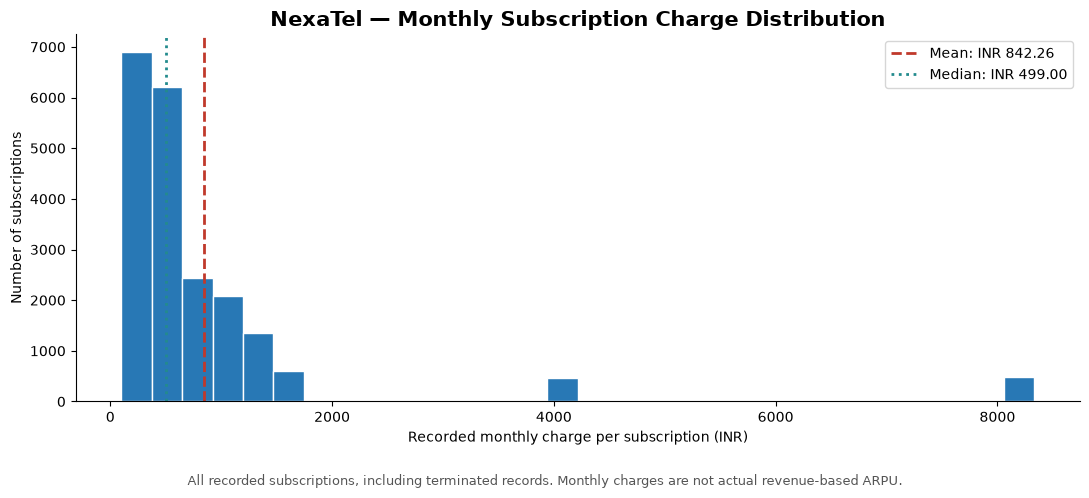

Chart saved: phase2_output\charts\08_monthly_charge_distribution.png


In [72]:
# Use recorded monthly charges from all subscriptions
monthly_charges = pd.to_numeric(
    subscriptions["monthly_charge_inr"],
    errors="coerce"
)

assert monthly_charges.notna().all(), "Missing or invalid charges found."
assert monthly_charges.ge(0).all(), "Negative monthly charges found."

mean_charge = monthly_charges.mean()
median_charge = monthly_charges.median()

print("Subscriptions included:", len(monthly_charges))
print("Unique customers:", subscriptions["customer_id"].nunique())
print(f"Mean monthly charge per subscription: INR {mean_charge:,.2f}")
print(f"Median monthly charge per subscription: INR {median_charge:,.2f}")

fig, ax = plt.subplots(figsize=(11, 5))

ax.hist(
    monthly_charges,
    bins=30,
    color="#2878B5",
    edgecolor="white"
)

ax.axvline(
    mean_charge,
    color="#C0392B",
    linestyle="--",
    linewidth=2,
    label=f"Mean: INR {mean_charge:,.2f}"
)

ax.axvline(
    median_charge,
    color="#238B8D",
    linestyle=":",
    linewidth=2,
    label=f"Median: INR {median_charge:,.2f}"
)

ax.set_title(
    "NexaTel — Monthly Subscription Charge Distribution",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Recorded monthly charge per subscription (INR)")
ax.set_ylabel("Number of subscriptions")
ax.spines[["top", "right"]].set_visible(False)
ax.legend()

fig.text(
    0.5, 0.02,
    "All recorded subscriptions, including terminated records. "
    "Monthly charges are not actual revenue-based ARPU.",
    ha="center",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])

chart_path = chart_folder / "08_monthly_charge_distribution.png"
fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_path)

# Chart-8 Observation

# Recorded monthly subscription charges have a mean of INR 842.26 and
a median of INR 499.00, with values ranging from INR 99.00 to INR
8,333.00. The higher mean indicates that expensive subscriptions
raise the average above the median. This chart covers 20,523
subscription records belonging to 19,000 customers, including
terminated subscriptions, and represents charges rather than
actual revenue-based ARPU.

Data-quality note: 251 customers marked Churned have a subscription
marked Active. This cross-table inconsistency is retained for review;
neither status was changed during EDA.

# Chart 9 — network quality versus churn

In [73]:
network = eda_tables["network_quality"].copy()

print("Network quality columns:")
print(network.columns.tolist())

print("\nSample records:")
display(network.head())

print("\nNumeric field summary:")
display(network.describe().round(3))

print("\nNetwork records per customer:")
display(
    network.groupby("customer_id")
    .size()
    .value_counts()
    .sort_index()
    .rename_axis("Records per customer")
    .rename("Customer count")
)

print(
    "\nCustomers without network records:",
    (~customers["customer_id"].isin(network["customer_id"])).sum()
)

Network quality columns:
['record_id', 'customer_id', 'city_id', 'month', 'avg_signal_strength_dbm', 'dropped_call_rate_pct', 'avg_download_speed_mbps', 'network_downtime_hours']

Sample records:


,record_id,customer_id,city_id,month,avg_signal_strength_dbm,dropped_call_rate_pct,avg_download_speed_mbps,network_downtime_hours
0,NQ00000001,C0000001,CT0026,03-2026,-74.3,3.15,25.1,0.87
1,NQ00000002,C0000001,CT0026,02-2026,-74.3,3.39,64.9,0.13
2,NQ00000003,C0000001,CT0026,01-2026,-74.3,1.75,68.7,0.46
3,NQ00000004,C0000002,CT0009,03-2026,-69.9,2.92,73.1,0.17
4,NQ00000005,C0000002,CT0009,02-2026,-69.9,3.02,75.3,0.33



Numeric field summary:


,avg_signal_strength_dbm,dropped_call_rate_pct,avg_download_speed_mbps,network_downtime_hours
count,57000.000,57000.000,57000.000,57000.000
mean,-67.992,2.401,49.058,0.718
std,7.844,1.291,22.531,0.633
min,-103.300,0.040,4.400,0.000
25%,-73.300,1.460,30.300,0.270
50%,-68.000,2.230,47.300,0.540
75%,-62.600,3.180,65.500,0.980
max,-50.600,9.820,118.700,6.960



Network records per customer:


Records per customer
3    19000
Name: Customer count, dtype: int64


Customers without network records: 0


,Customers,Mean_dropped_call_pct,Median_dropped_call_pct
customer_status,,,
Active,15494,2.358,2.290
Churned,3506,2.594,2.538


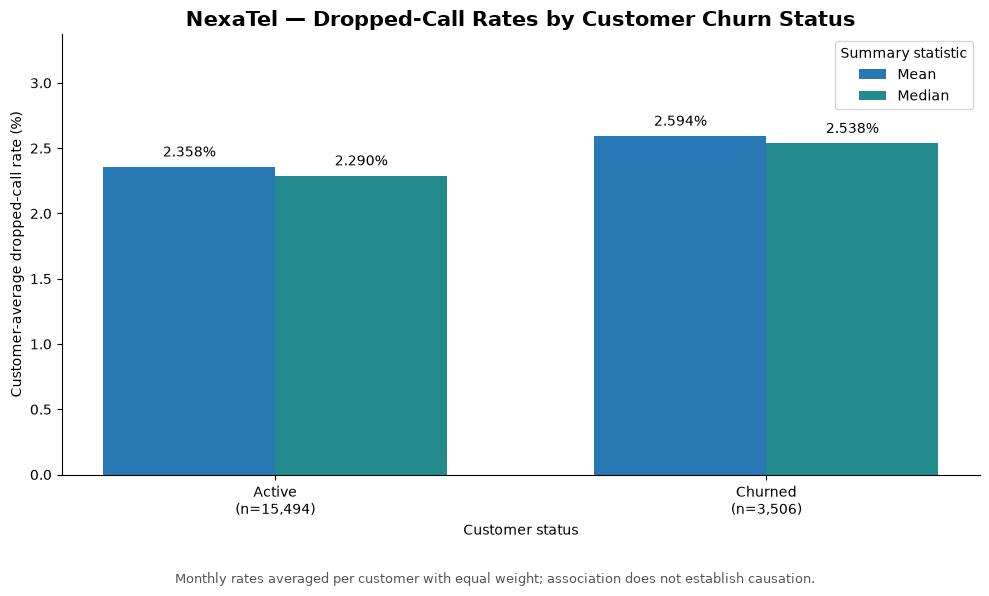

Chart saved: phase2_output\charts\09_network_quality_vs_churn.png


In [74]:
# Validate monthly records and percentage values
assert not network.duplicated(["customer_id", "month"]).any(), (
    "Duplicate customer-month network records found."
)

drop_rates = pd.to_numeric(
    network["dropped_call_rate_pct"], errors="coerce"
)
assert drop_rates.notna().all(), "Missing or invalid dropped-call rates."
assert drop_rates.between(0, 100).all(), "Rates outside 0–100%."

network = network.assign(dropped_call_rate_pct=drop_rates)

# Give each customer one average
customer_network = (
    network.groupby("customer_id", as_index=False)
    .agg(
        avg_dropped_call_pct=("dropped_call_rate_pct", "mean")
    )
)

network_analysis = customers[
    ["customer_id", "customer_status"]
].merge(
    customer_network,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

assert network_analysis["avg_dropped_call_pct"].notna().all(), (
    "Some customers have no network measurements."
)

network_summary = (
    network_analysis.groupby("customer_status")
    .agg(
        Customers=("customer_id", "size"),
        Mean_dropped_call_pct=("avg_dropped_call_pct", "mean"),
        Median_dropped_call_pct=("avg_dropped_call_pct", "median")
    )
    .reindex(["Active", "Churned"])
)

display(network_summary.round(3))

# Grouped bars: mean and median for each customer-status group
plot_data = network_summary.reindex(["Active", "Churned"])

x = list(range(len(plot_data)))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

mean_bars = ax.bar(
    [position - width / 2 for position in x],
    plot_data["Mean_dropped_call_pct"],
    width,
    label="Mean",
    color="#2878B5"
)

median_bars = ax.bar(
    [position + width / 2 for position in x],
    plot_data["Median_dropped_call_pct"],
    width,
    label="Median",
    color="#238B8D"
)

for bars in [mean_bars, median_bars]:
    ax.bar_label(
        bars,
        labels=[f"{bar.get_height():.3f}%" for bar in bars],
        padding=5
    )

ax.set_xticks(x)
ax.set_xticklabels([
    f"{status}\n(n={int(count):,})"
    for status, count in zip(
        plot_data.index, plot_data["Customers"]
    )
])

ax.set_title(
    "NexaTel — Dropped-Call Rates by Customer Churn Status",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Customer status")
ax.set_ylabel("Customer-average dropped-call rate (%)")

maximum = plot_data[
    ["Mean_dropped_call_pct", "Median_dropped_call_pct"]
].max().max()

ax.set_ylim(0, maximum * 1.3)
ax.legend(title="Summary statistic")
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.5, 0.02,
    "Monthly rates averaged per customer with equal weight; "
    "association does not establish causation.",
    ha="center",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])

chart_path = chart_folder / "09_network_quality_vs_churn.png"
fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_path)

# Chart -9 Observation

 # The mean of customer-average dropped-call rates is 2.594% for Churned
customers and 2.358% for Active customers—a difference of approximately
0.236 percentage points. Median customer-average rates follow the same
pattern, at 2.538% and 2.290%, respectively. This is a descriptive
association; it does not establish that network problems preceded
or caused churn.

# Chart 10 — retention campaign outcomes

In [75]:
retention = eda_tables["retention_campaigns"].copy()

print("Retention campaign columns:")
print(retention.columns.tolist())

print("\nSample records:")
display(retention.head())

print("\nMissing values:")
display(retention.isna().sum())

print("\nCampaign records:", len(retention))
print("Unique customers:", retention["customer_id"].nunique())

print("\nCampaign records per customer:")
display(
    retention.groupby("customer_id")
    .size()
    .value_counts()
    .sort_index()
    .rename_axis("Records per customer")
    .rename("Customer count")
)

# Display categories in response/outcome/retention fields
outcome_columns = [
    col for col in retention.columns
    if col != "customer_id"
    and any(
        keyword in col.lower()
        for keyword in ["response", "outcome", "retained", "status"]
    )
]

for col in outcome_columns:
    print(f"\n{col}:")
    display(retention[col].value_counts(dropna=False))

Retention campaign columns:
['campaign_id', 'customer_id', 'campaign_name', 'offer_type', 'contact_date', 'channel', 'response', 'retained_flag']

Sample records:


,campaign_id,customer_id,campaign_name,offer_type,contact_date,channel,response,retained_flag
0,RTC0000001,C0000004,Renewal Nudge,Annual Plan Discount,2025-09-04,SMS,Declined,Yes
1,RTC0000002,C0000009,Renewal Nudge,Cashback Voucher,2026-01-08,Call,Declined,Yes
2,RTC0000003,C0000015,Loyalty Save,Extra Data 50GB,2025-02-23,WhatsApp,Accepted,Yes
3,RTC0000004,C0000016,At-Risk Outreach,Free OTT 3 Months,2026-01-08,WhatsApp,Accepted,No
4,RTC0000005,C0000017,Loyalty Save,Plan Upgrade Offer,2025-05-22,Email,Accepted,No



Missing values:


campaign_id      0
customer_id      0
campaign_name    0
offer_type       0
contact_date     0
channel          0
response         0
retained_flag    0
dtype: int64


Campaign records: 6475
Unique customers: 6475

Campaign records per customer:


Records per customer
1    6475
Name: Customer count, dtype: int64


response:


response
Accepted       2982
Declined       1877
No Response    1616
Name: count, dtype: int64


retained_flag:


retained_flag
Yes    5337
No     1138
Name: count, dtype: int64

,Customers,Retained,Response Share %,Retained Share %
response,,,,
Accepted,2982,2589,46.05,86.82
Declined,1877,1486,28.99,79.17
No Response,1616,1262,24.96,78.09


Overall recorded retained share: 82.42%


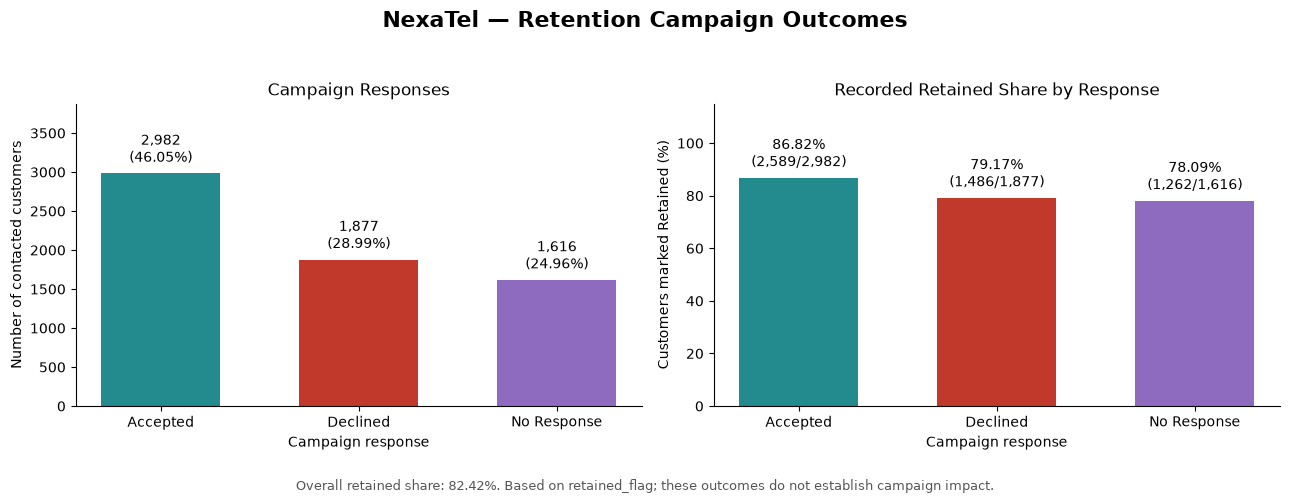

Chart saved: phase2_output\charts\10_retention_campaign_outcomes.png


In [76]:
response_order = ["Accepted", "Declined", "No Response"]

assert retention["customer_id"].is_unique
assert retention["response"].isin(response_order).all()
assert retention["retained_flag"].isin(["Yes", "No"]).all()

retention_analysis = retention.copy()
retention_analysis["retained"] = (
    retention_analysis["retained_flag"].eq("Yes")
)

retention_summary = (
    retention_analysis.groupby("response")
    .agg(
        Customers=("customer_id", "size"),
        Retained=("retained", "sum")
    )
    .reindex(response_order)
)

retention_summary["Response Share %"] = (
    retention_summary["Customers"] / len(retention_analysis) * 100
)
retention_summary["Retained Share %"] = (
    retention_summary["Retained"]
    / retention_summary["Customers"] * 100
)

overall_retained_pct = retention_analysis["retained"].mean() * 100

display(retention_summary.round(2))
print(f"Overall recorded retained share: {overall_retained_pct:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = ["#238B8D", "#C0392B", "#8E6BBE"]

# Response counts
bars = axes[0].bar(
    retention_summary.index,
    retention_summary["Customers"],
    color=colors,
    width=0.6
)

axes[0].bar_label(
    bars,
    labels=[
        f"{count:,}\n({share:.2f}%)"
        for count, share in zip(
            retention_summary["Customers"],
            retention_summary["Response Share %"]
        )
    ],
    padding=5
)
axes[0].set_title("Campaign Responses")
axes[0].set_ylabel("Number of contacted customers")
axes[0].set_ylim(0, retention_summary["Customers"].max() * 1.3)

# Retained share within each response group
bars = axes[1].bar(
    retention_summary.index,
    retention_summary["Retained Share %"],
    color=colors,
    width=0.6
)

axes[1].bar_label(
    bars,
    labels=[
        f"{share:.2f}%\n({kept:,}/{count:,})"
        for share, kept, count in zip(
            retention_summary["Retained Share %"],
            retention_summary["Retained"],
            retention_summary["Customers"]
        )
    ],
    padding=5
)
axes[1].set_title("Recorded Retained Share by Response")
axes[1].set_ylabel("Customers marked Retained (%)")
axes[1].set_ylim(0, 115)

for ax in axes:
    ax.set_xlabel("Campaign response")
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "NexaTel — Retention Campaign Outcomes",
    fontsize=16,
    fontweight="bold"
)
fig.text(
    0.5, 0.02,
    f"Overall retained share: {overall_retained_pct:.2f}%. "
    "Based on retained_flag; these outcomes do not establish campaign impact.",
    ha="center",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.07, 1, 0.94])

chart_path = chart_folder / "10_retention_campaign_outcomes.png"
fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_path)

# Chart-10 Observation

# Among 6,475 contacted customers, 46.05% accepted the offer, 28.99%
declined, and 24.96% gave no response. Recorded retained share was
highest among those who accepted (86.82%), compared with 79.17%
among those who declined and 78.09% among those who did not respond.
Overall, 82.42% were marked retained, but these observational results
do not establish how much retention was caused by the campaigns.

In [77]:
expected_charts = [
    "01_overall_churn.png",
    "02_churn_by_billing_cycle.png",
    "03_churn_by_tenure.png",
    "04_churn_by_unresolved_complaints.png",
    "05_churn_by_customer_segment.png",
    "06_top10_states_by_churned_customers.png",
    "07_average_data_usage_by_city_tier.png",
    "08_monthly_charge_distribution.png",
    "09_network_quality_vs_churn.png",
    "10_retention_campaign_outcomes.png"
]

chart_check = pd.DataFrame({
    "Chart file": expected_charts,
    "Saved and nonempty": [
        (chart_folder / name).is_file()
        and (chart_folder / name).stat().st_size > 0
        for name in expected_charts
    ]
})

display(chart_check)

assert chart_check["Saved and nonempty"].all(), (
    "Some chart files are missing or empty."
)

print("All 10 required chart PNGs are present.")

,Chart file,Saved and nonempty
0,01_overall_churn.png,True
1,02_churn_by_billing_cycle.png,True
2,03_churn_by_tenure.png,True
3,04_churn_by_unresolved_complaints.png,True
4,05_churn_by_customer_segment.png,True
5,06_top10_states_by_churned_customers.png,True
6,07_average_data_usage_by_city_tier.png,True
7,08_monthly_charge_distribution.png,True
8,09_network_quality_vs_churn.png,True
9,10_retention_campaign_outcomes.png,True


All 10 required chart PNGs are present.
